In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [ ]:
from google.colab import files
files.upload()

Saving Ocean_Monitoring_Status_Perfect_Accuracy.csv to Ocean_Monitoring_Status_Perfect_Accuracy (1).csv


{'Ocean_Monitoring_Status_Perfect_Accuracy (1).csv': b'Water_Temperature_C,Salinity_PSU,Dissolved_Oxygen_mg_L,pH_Level,Depth_Meters,Current_Speed_m_s,Turbidity_NTU,Nitrate_mg_L,Chlorophyll_ug_L,Sensor_Type,Sampling_Region,Sampling_Month,Vessel_Type,Environmental_Status_Code,Environmental_Status\n25.44,34.17,4.65,7.811,2233.4,2.22,46.4,47.23,38.31,Acoustic,Open Ocean,5,Research Ship,0,NORMAL\n0.88,34.77,11.05,7.249,3984.7,1.86,65.94,29.54,43.76,Acoustic,Estuary,11,Drone,0,NORMAL\n11.85,30.62,12.16,7.575,1923.0,2.74,57.07,14.56,2.73,CTD,Estuary,3,Glider,127,WATCH\n7.85,32.01,4.3,7.802,1542.4,3.12,73.77,58.05,1.16,CTD,Open Ocean,9,Drone,0,NORMAL\n23.27,33.39,4.12,7.585,4257.4,1.35,79.74,74.83,36.59,Acoustic,Open Ocean,7,Glider,255,CRITICAL\n31.66,36.14,1.62,7.814,1327.7,1.26,99.46,12.11,39.61,Acoustic,Coastal,9,Glider,0,NORMAL\n0.59,31.47,5.66,8.02,3573.7,2.54,98.38,43.24,29.09,CTD,Estuary,6,Glider,255,CRITICAL\n15.16,39.45,1.22,8.279,368.2,0.34,51.44,2.35,10.09,Satellite,Coastal,5,Glider

In [ ]:
url = "/content/Ocean_Monitoring_Status_Perfect_Accuracy.csv"
df = pd.read_csv(url)
df.head()

,Water_Temperature_C,Salinity_PSU,Dissolved_Oxygen_mg_L,pH_Level,Depth_Meters,Current_Speed_m_s,Turbidity_NTU,Nitrate_mg_L,Chlorophyll_ug_L,Sensor_Type,Sampling_Region,Sampling_Month,Vessel_Type,Environmental_Status_Code,Environmental_Status
0,25.44,34.17,4.65,7.811,2233.4,2.22,46.40,47.23,38.31,Acoustic,Open Ocean,5,Research Ship,0,NORMAL
1,0.88,34.77,11.05,7.249,3984.7,1.86,65.94,29.54,43.76,Acoustic,Estuary,11,Drone,0,NORMAL
2,11.85,30.62,12.16,7.575,1923.0,2.74,57.07,14.56,2.73,CTD,Estuary,3,Glider,127,WATCH
3,7.85,32.01,4.30,7.802,1542.4,3.12,73.77,58.05,1.16,CTD,Open Ocean,9,Drone,0,NORMAL
4,23.27,33.39,4.12,7.585,4257.4,1.35,79.74,74.83,36.59,Acoustic,Open Ocean,7,Glider,255,CRITICAL


In [ ]:
# Select Turbidity_NTU and Dissolved_Oxygen_mg_L as feature variables for clustering
X = df[['Turbidity_NTU', 'Dissolved_Oxygen_mg_L']]
print("Features selected for clustering: Turbidity_NTU and Dissolved_Oxygen_mg_L")

Features selected for clustering: Turbidity_NTU and Dissolved_Oxygen_mg_L


In [ ]:
# Apply StandardScaler to normalize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling complete using StandardScaler")

Feature scaling complete using StandardScaler


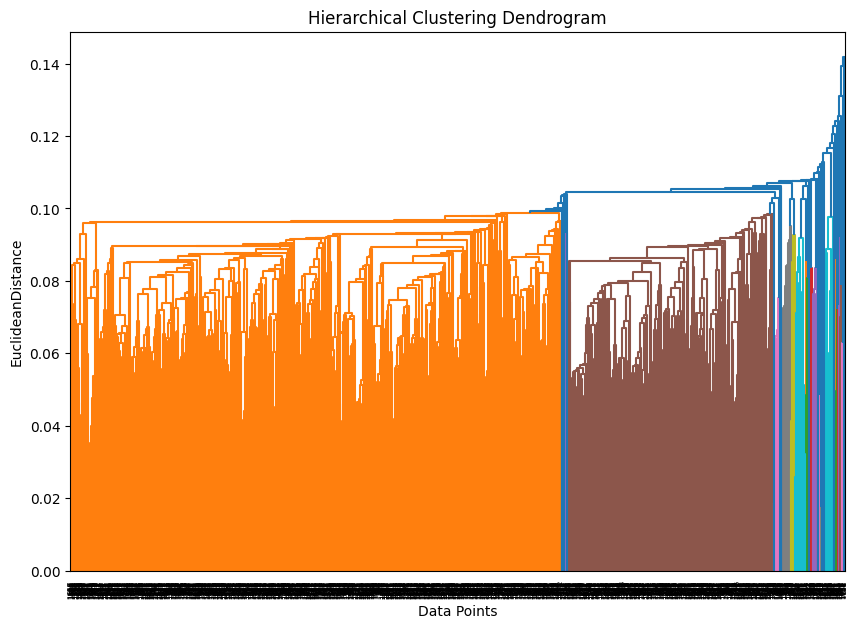

In [ ]:
#plot dendrogram
linked=linkage(X_scaled,method='single')
plt.figure(figsize=(10,7))
dendrogram(linked,orientation='top',distance_sort='descending',show_leaf_counts=True)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('EuclideanDistance')
plt.show()

In [ ]:
# Initialize Agglomerative Clustering with 3 clusters and fit on the scaled features
hc = AgglomerativeClustering(n_clusters=3)
labels = hc.fit_predict(X_scaled)
print("Model trained successfully")

Model trained successfully


In [ ]:
# Assign cluster labels to the original dataset and display the first 5 rows
df['Cluster'] = labels
df[['Turbidity_NTU', 'Dissolved_Oxygen_mg_L', 'Cluster']].head()

,Turbidity_NTU,Dissolved_Oxygen_mg_L,Cluster
0,46.40,4.65,1
1,65.94,11.05,2
2,57.07,12.16,0
3,73.77,4.30,1
4,79.74,4.12,1


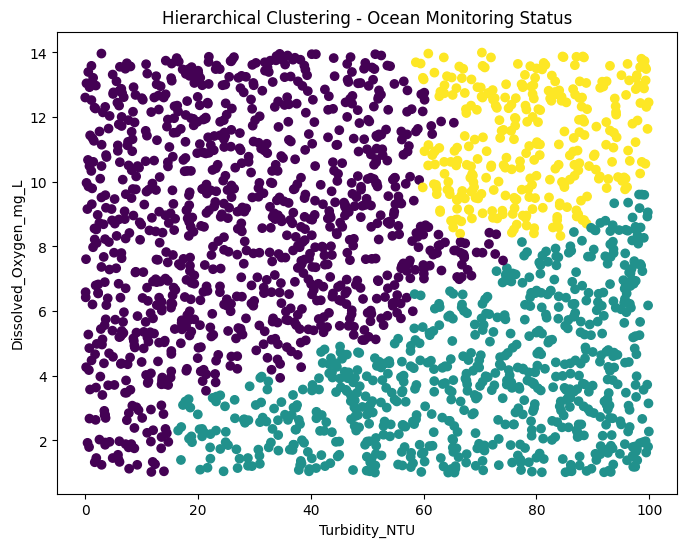

In [ ]:
# Visualize the clusters
plt.figure(figsize=(8,6))
plt.scatter(
    X['Turbidity_NTU'],
    X['Dissolved_Oxygen_mg_L'],
    c=labels,
    cmap='viridis'
)

plt.xlabel("Turbidity_NTU")
plt.ylabel("Dissolved_Oxygen_mg_L")
plt.title("Hierarchical Clustering - Ocean Monitoring Status")
plt.show()

In [ ]:
# Calculate and display model evaluation metrics: Silhouette Score, Davies-Bouldin Index
score = silhouette_score(X_scaled, labels)
print("Silhouette Score:", score)

db_score = davies_bouldin_score(X_scaled, labels)
print("Davies-Bouldin Index:", db_score)

Silhouette Score: 0.3217757351923775
Davies-Bouldin Index: 0.91270081848098
